# 05. Linear Regression — Future Customer Spending Prediction

**Project:** E-Commerce Customer Analytics  
**Objective:** Predict each customer's **future 90-day spending (`future_spending`)** using strictly historical pre-cutoff transaction features—without any temporal data leakage—and evaluate Linear Regression honestly against simple baselines and outlier checks.

> **Chronological Zero-Leakage Design (`275-Day Observation -> 90-Day Q4 Target`):**
> - **Training Cohort (`2009–2010`):** Observation `2009-12-10` to `2010-09-10` (`275` days) $\rightarrow$ Future Target `2010-09-11` to `2010-12-09` (`90` days)
> - **Test Cohort (`2010–2011`):** Observation `2010-12-10` to `2011-09-10` (`275` days) $\rightarrow$ Future Target `2011-09-11` to `2011-12-09` (`90` days)
> - **Why this split works:** Zero calendar overlap between Train and Test, identical observation duration (`275` days), and identical Q4 holiday seasonal target windows (`Sep 11 – Dec 9`).

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.regression import (
    FEATURE_COLUMNS,
    TARGET_COLUMN,
    build_temporal_cohort,
    evaluate_regression_suite,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

TX_PATH = PROJECT_ROOT / "dataset" / "processed" / "analytics" / "transaction_features.csv"
VIZ_DIR = PROJECT_ROOT / "visualizations"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
for d in (VIZ_DIR, MODELS_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

tx_df = pd.read_csv(
    TX_PATH,
    dtype={"invoice": "string", "stock_code": "string", "customer_id": "Int64"},
    parse_dates=["invoice_date"],
)

train_df = build_temporal_cohort(tx_df, "2009-12-10", "2010-09-11", "2010-09-11", "2010-12-10")
test_df = build_temporal_cohort(tx_df, "2010-12-10", "2011-09-11", "2011-09-11", "2011-12-10")

# Explicit chronological leakage verification
assert train_df["last_purchase_date"].max() < pd.Timestamp("2010-09-11")
assert test_df["last_purchase_date"].max() < pd.Timestamp("2011-09-11")

print(f"Train cohort: {len(train_df):,} customers | Missing values in features/target: {int(train_df[FEATURE_COLUMNS + [TARGET_COLUMN]].isna().sum().sum())}")
print(f"Test  cohort: {len(test_df):,} customers | Missing values in features/target: {int(test_df[FEATURE_COLUMNS + [TARGET_COLUMN]].isna().sum().sum())}")
print(f"Train target zero/non-positive rate: {(train_df[TARGET_COLUMN] <= 0).mean() * 100:.1f}% ({int((train_df[TARGET_COLUMN] <= 0).sum()):,} customers)")
print(f"Test  target zero/non-positive rate: {(test_df[TARGET_COLUMN] <= 0).mean() * 100:.1f}% ({int((test_df[TARGET_COLUMN] <= 0).sum()):,} customers)")

display(train_df[["customer_id"] + FEATURE_COLUMNS + [TARGET_COLUMN]].head(6))

Train cohort: 3,270 customers | Missing values in features/target: 0
Test  cohort: 3,248 customers | Missing values in features/target: 0
Train target zero/non-positive rate: 41.7% (1,365 customers)
Test  target zero/non-positive rate: 42.6% (1,383 customers)


,customer_id,hist_spending,hist_frequency,hist_quantity,hist_aov,hist_unique_products,hist_recency,hist_tenure,hist_cancelled_orders,future_spending
0,12346,-146.24,2,10,-73.12,24,75,193,1,-1.00
1,12349,1268.52,2,474,634.26,47,116,135,0,1402.62
2,12355,488.21,1,303,488.21,22,113,113,0,0.00
3,12358,268.10,1,281,268.10,17,96,96,0,1021.08
4,12359,1157.34,4,264,289.33,52,81,269,2,551.33
5,12360,740.04,3,755,246.68,44,109,201,1,810.79


### Chronological Cohort & Leakage Prevention Analysis
- Both cohorts align exactly across **275 observation days** followed by **90 future target days**, with **zero overlap** between the training year (`<= 2010-12-09`) and test year (`>= 2010-12-10`).
- Explicit date assertions confirm every historical feature (`hist_spending`, `hist_frequency`, `hist_quantity`, `hist_aov`, `hist_unique_products`, `hist_recency`, `hist_tenure`, `hist_cancelled_orders`) uses strictly pre-cutoff dates (`< 2010-09-11` for Train, `< 2011-09-11` for Test).
- Missing values across all `8` predictors and `future_spending` are **`0`** (customers with no orders during the 90-day future window rightly receive `future_spending = 0.0`, accounting for `41.7%` in Train and `42.6%` in Test).

Train feature & target distribution (with 95th/99th percentiles):


,hist_spending,hist_frequency,hist_quantity,hist_aov,hist_unique_products,hist_recency,hist_tenure,hist_cancelled_orders,future_spending
count,3270.00,3270.00,3270.00,3270.00,3270.00,3270.00,3270.00,3270.00,3270.00
mean,1551.38,3.56,1044.96,348.70,52.10,88.17,171.50,0.83,729.29
std,6783.89,5.89,5874.96,465.92,69.92,71.51,75.61,1.95,2923.92
min,-10953.50,1.00,-8.00,-10953.50,1.00,1.00,1.00,0.00,-13238.70
25%,262.61,1.00,127.00,167.19,15.00,26.00,115.00,0.00,0.00
50%,575.81,2.00,317.00,279.24,32.00,72.00,185.00,0.00,213.90
75%,1334.17,4.00,795.75,406.88,65.00,137.00,233.00,1.00,697.75
95%,4680.52,10.00,2710.90,891.29,161.55,226.00,272.00,4.00,2502.35
99%,14597.34,26.31,9761.05,1752.35,307.00,271.00,275.00,7.00,7821.08
max,241674.73,114.00,218094.00,10877.18,1299.00,275.00,275.00,38.00,79340.76


Test feature & target distribution (with 95th/99th percentiles):


,hist_spending,hist_frequency,hist_quantity,hist_aov,hist_unique_products,hist_recency,hist_tenure,hist_cancelled_orders,future_spending
count,3248.00,3248.00,3248.00,3248.00,3248.00,3248.00,3248.00,3248.00,3248.00
mean,1486.61,3.43,895.05,362.07,48.98,89.11,171.61,0.71,790.80
std,5558.22,5.47,3531.13,419.45,65.73,72.93,75.00,1.74,4069.52
min,-1591.20,1.00,-622.00,-1591.20,1.00,2.00,2.00,0.00,-468.32
25%,252.44,1.00,129.00,163.96,14.00,26.00,117.00,0.00,0.00
50%,545.05,2.00,309.00,275.40,29.00,69.00,184.00,0.00,180.35
75%,1329.58,4.00,761.25,413.41,61.00,143.00,234.00,1.00,699.95
95%,4397.22,10.00,2614.25,888.18,162.00,229.00,271.00,3.00,2442.02
99%,13275.63,21.53,8707.72,1978.01,272.06,270.00,275.00,7.00,9521.42
max,177585.62,115.00,126972.00,7178.63,1187.00,275.00,275.00,29.00,124206.55


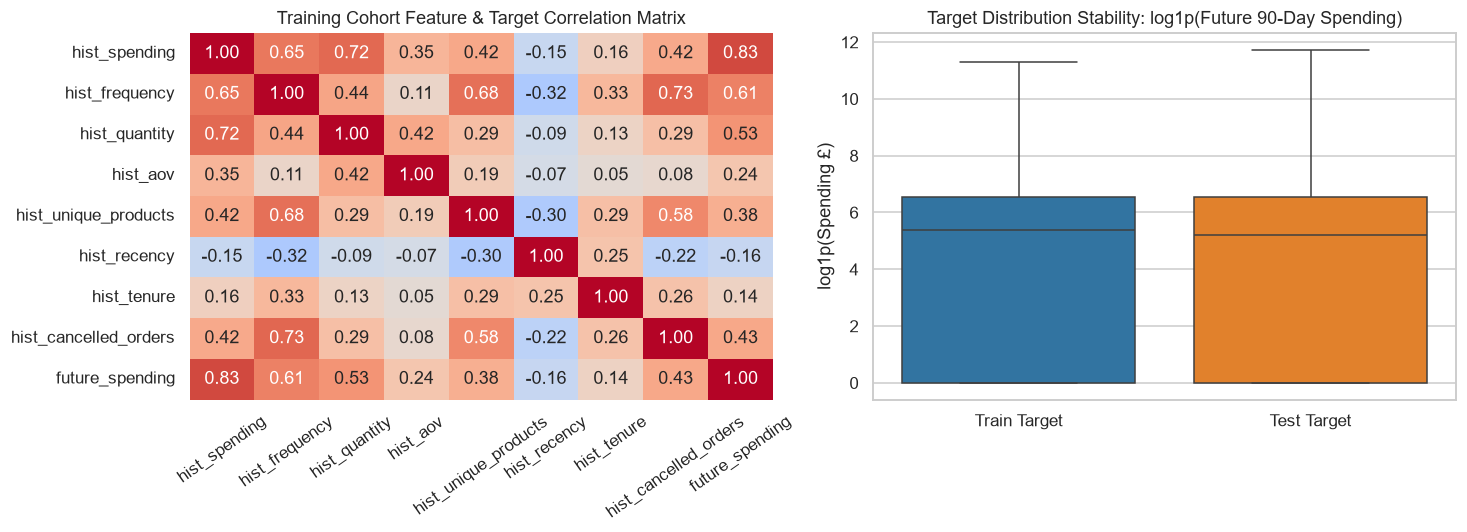

In [2]:
print("Train feature & target distribution (with 95th/99th percentiles):")
display(train_df[FEATURE_COLUMNS + [TARGET_COLUMN]].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(2))

print("Test feature & target distribution (with 95th/99th percentiles):")
display(test_df[FEATURE_COLUMNS + [TARGET_COLUMN]].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))
corr_matrix = train_df[FEATURE_COLUMNS + [TARGET_COLUMN]].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0], cbar=False)
axes[0].set_title("Training Cohort Feature & Target Correlation Matrix")
axes[0].tick_params(axis="x", rotation=35)

# Compare extreme target skew via log1p boxplot vs linear outliers
sns.boxplot(
    data=pd.DataFrame({
        "Train Target": np.log1p(train_df[TARGET_COLUMN].clip(lower=0)),
        "Test Target": np.log1p(test_df[TARGET_COLUMN].clip(lower=0)),
    }),
    palette=["#1f77b4", "#ff7f0e"],
    ax=axes[1],
)
axes[1].set_title("Target Distribution Stability: log1p(Future 90-Day Spending)")
axes[1].set_ylabel("log1p(Spending £)")

plt.tight_layout()
fig.savefig(VIZ_DIR / "05_lr_outlier_and_corr.png", dpi=150, bbox_inches="tight")
plt.show()

### Feature Correlations & Outlier Assessment
- **Strongest Linear Drivers:** In the Training cohort, `hist_spending` (`r = 0.83`) and `hist_frequency` (`r = 0.61`) correlate most strongly with `future_spending`, followed by `hist_quantity` (`r = 0.53`), `hist_cancelled_orders` (`r = 0.43`), and `hist_unique_products` (`r = 0.38`). Notice `hist_spending` and `hist_quantity` are strongly collinear (`r = 0.72`).
- **Extreme Outlier Skew:** In Test, `99%` of customers spend `<= £13,276` historically and the `99th percentile` future target sits in the upper tail, yet maximum future spending stretches up to **`£124,206.55`** (`median = £180.35`; `Train max = £79,340.76`). Because Ordinary Least Squares (OLS) minimizes *squared* errors, those top `1%` wholesale accounts exert huge leverage on RMSE and R².

Chronological Evaluation Comparison (Baselines vs. Linear Regression & Outlier Checks):


,model_name,split,n_samples,mae,mse,rmse,r2_score
0,Baseline (Mean),test,3248,935.3463,1.655966e+07,4069.3563,-0.0002
1,Baseline (Median),test,3248,775.4332,1.688869e+07,4109.5847,-0.0201
2,Simple OLS (hist_spending only),test,3248,596.7063,7.468920e+06,2732.9325,0.5489
3,Linear Regression (Full Pipeline),train,3270,565.7596,2.450783e+06,1565.4978,0.7132
4,Linear Regression (Full Pipeline),test,3248,586.6102,7.432258e+06,2726.2167,0.5511
5,Linear Regression (Trained w/o Top 1% Target O...,test,3248,594.4684,9.037144e+06,3006.1842,0.4541
6,Linear Regression (Full Pipeline),test_excl_top1pct_outliers,3215,429.2261,5.159313e+05,718.2836,0.3828


Model Intercept (at scaled feature mean): £729.29


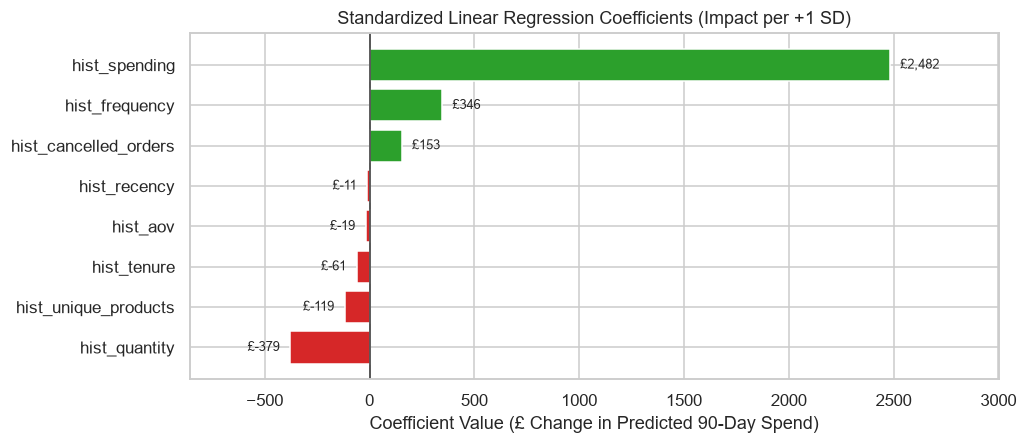

In [3]:
pipeline, eval_df, pred_df = evaluate_regression_suite(train_df, test_df, FEATURE_COLUMNS)
print("Chronological Evaluation Comparison (Baselines vs. Linear Regression & Outlier Checks):")
display(eval_df)

# Inspect standardized coefficients
lr_model = pipeline.named_steps["regressor"]
coef_series = pd.Series(lr_model.coef_, index=FEATURE_COLUMNS).sort_values()
print(f"Model Intercept (at scaled feature mean): £{lr_model.intercept_:,.2f}")

fig, ax = plt.subplots(figsize=(9.5, 4.2))
colors = ["#d62728" if c < 0 else "#2ca02c" for c in coef_series.values]
bars = ax.barh(coef_series.index, coef_series.values, color=colors)
ax.axvline(0, color="#333333", linewidth=1)
ax.set_title("Standardized Linear Regression Coefficients (Impact per +1 SD)")
ax.set_xlabel("Coefficient Value (£ Change in Predicted 90-Day Spend)")
for b, v in zip(bars, coef_series.values):
    offset = 50 if v >= 0 else -50
    ha = "left" if v >= 0 else "right"
    ax.text(v + offset, b.get_y() + b.get_height() / 2, f"£{v:,.0f}", va="center", ha=ha, fontsize=8.5)
ax.set_xlim(coef_series.min() - 480, coef_series.max() + 520)
plt.tight_layout()
fig.savefig(VIZ_DIR / "05_lr_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

### Model Evaluation & Metric Interpretation
- **What each metric means:**
  - **MAE (`£586.61` on Test):** Average absolute difference between predicted and actual 90-day spending (beats Mean Baseline `£935.35` by `37.3%` and Median Baseline `£775.43` by `24.4%`).
  - **MSE (`7,432,257.55` on Test) & RMSE (`£2,726.22`):** Square-root of mean squared error, heavily penalizing large mistakes on high-spend outliers (improves substantially over Mean Baseline `£4,069.36`).
  - **R² Score (`0.5511` on Test vs. `0.7132` on Train):** The model explains **`55.11%`** of variance in unseen Q4 2011 customer spending (compared to `-0.0002` for the Mean Baseline), outperforming the 1-feature `hist_spending` baseline (`R² = 0.5489`).
- **Outlier Impact Finding:** Excluding the top `1%` Test spenders from *evaluation* reduces MAE to **`£429.23`** and plunges RMSE by nearly **4×** to **`£718.28`** (`R² = 0.3828`). Conversely, dropping top `1%` outliers from *training* degrades overall Test RMSE to **`£3,006.18`** (`R² = 0.4541`) because the model loses information about real repeat wholesale accounts!
- **Coefficient Note:** Notice `hist_spending` carries a large positive weight (`+£2,482` per +1 SD), while `hist_quantity` carries a negative adjustment (`-£379`) due to multicollinearity with spending; `hist_frequency` (`+£346`) adds positive purchase-momentum signal.

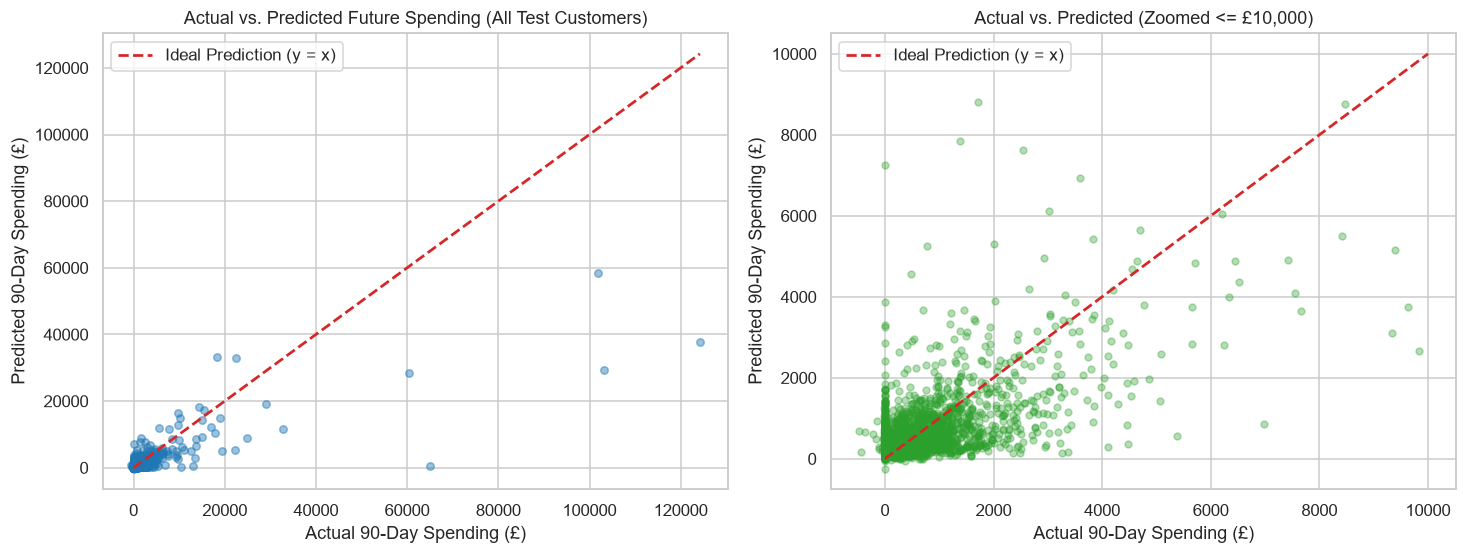

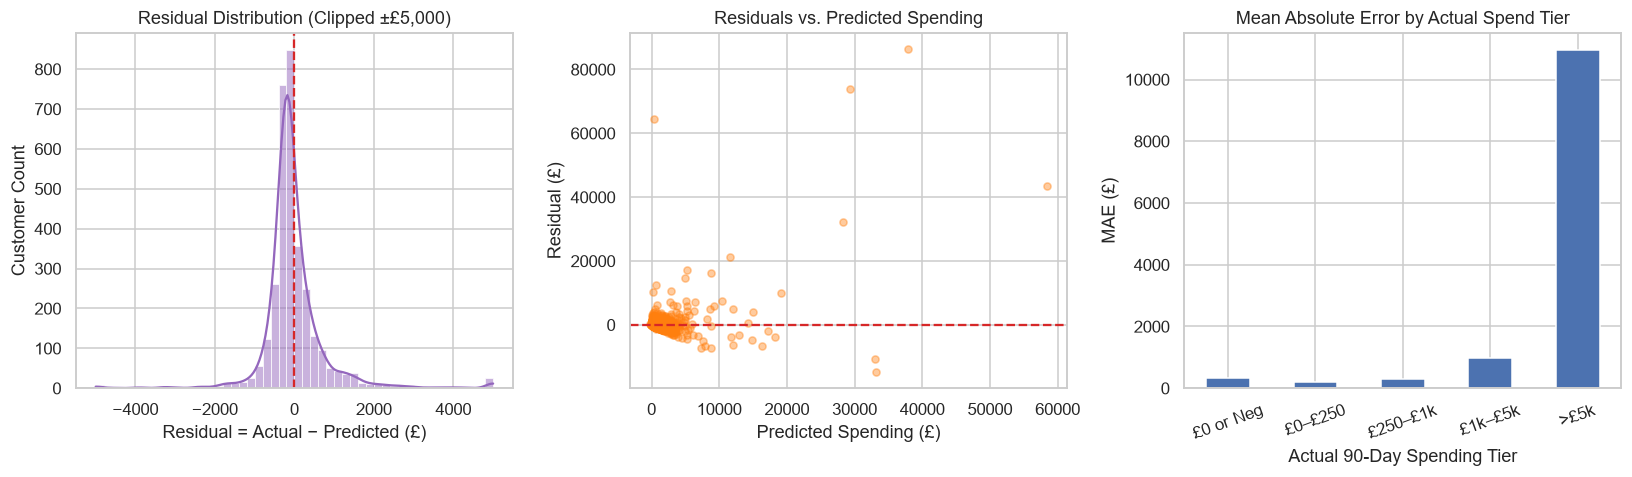

Error Summary by Actual 90-Day Spending Tier:


,count,mean,median
actual_tier,,,
£0 or Neg,1383,327.63,249.11
£0–£250,376,201.64,129.76
£250–£1k,929,314.59,239.31
£1k–£5k,506,973.32,803.46
>£5k,54,10956.10,4929.50



Top 8 Largest Test Prediction Errors:


,customer_id,hist_spending,hist_frequency,hist_recency,future_spending,predicted_spending,residual,abs_error,actual_tier
3147,18102,104397.33,23,9,124206.55,37875.70,86330.85,86330.85,>£5k
2802,17450,82202.22,21,6,103091.11,29353.70,73737.41,73737.41,>£5k
992,14096,134.23,3,2,64920.11,401.10,64519.01,64519.01,>£5k
1308,14646,177585.62,42,3,101903.40,58477.38,43426.02,43426.02,>£5k
1452,14911,67580.09,104,4,60467.06,28337.75,32129.31,32129.31,>£5k
2395,16684,33122.02,18,44,32770.06,11650.37,21119.69,21119.69,>£5k
2767,17389,8970.48,25,6,22329.60,5280.14,17049.46,17049.46,>£5k
989,14088,25431.57,7,39,24983.92,8816.92,16167.00,16167.00,>£5k


In [4]:
# Chart A: Actual vs. Predicted (Full Scale & Zoomed <= £10,000)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

axes[0].scatter(pred_df["future_spending"], pred_df["predicted_spending"], alpha=0.45, color="#1f77b4", s=24)
max_val = max(pred_df["future_spending"].max(), pred_df["predicted_spending"].max())
axes[0].plot([0, max_val], [0, max_val], color="#d62728", linestyle="--", linewidth=1.8, label="Ideal Prediction (y = x)")
axes[0].set_title("Actual vs. Predicted Future Spending (All Test Customers)")
axes[0].set_xlabel("Actual 90-Day Spending (£)")
axes[0].set_ylabel("Predicted 90-Day Spending (£)")
axes[0].legend()

zoom = pred_df[(pred_df["future_spending"] <= 10000) & (pred_df["predicted_spending"].between(-1000, 10000))]
axes[1].scatter(zoom["future_spending"], zoom["predicted_spending"], alpha=0.35, color="#2ca02c", s=20)
axes[1].plot([0, 10000], [0, 10000], color="#d62728", linestyle="--", linewidth=1.8, label="Ideal Prediction (y = x)")
axes[1].set_title("Actual vs. Predicted (Zoomed <= £10,000)")
axes[1].set_xlabel("Actual 90-Day Spending (£)")
axes[1].set_ylabel("Predicted 90-Day Spending (£)")
axes[1].legend()

plt.tight_layout()
fig.savefig(VIZ_DIR / "05_lr_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

# Chart B: Residual Distribution, Residuals vs Predicted, and Error by Spending Tier
fig2, axes2 = plt.subplots(1, 3, figsize=(15, 4.5))

res_clipped = pred_df["residual"].clip(-5000, 5000)
sns.histplot(res_clipped, bins=50, kde=True, color="#9467bd", ax=axes2[0])
axes2[0].axvline(0, color="#d62728", linestyle="--", linewidth=1.5)
axes2[0].set_title("Residual Distribution (Clipped ±£5,000)")
axes2[0].set_xlabel("Residual = Actual − Predicted (£)")
axes2[0].set_ylabel("Customer Count")

axes2[1].scatter(pred_df["predicted_spending"], pred_df["residual"], alpha=0.4, color="#ff7f0e", s=22)
axes2[1].axhline(0, color="#d62728", linestyle="--", linewidth=1.5)
axes2[1].set_title("Residuals vs. Predicted Spending")
axes2[1].set_xlabel("Predicted Spending (£)")
axes2[1].set_ylabel("Residual (£)")

pred_df["actual_tier"] = pd.cut(
    pred_df["future_spending"],
    bins=[-1e9, 0.0, 250.0, 1000.0, 5000.0, 1e9],
    labels=["£0 or Neg", "£0–£250", "£250–£1k", "£1k–£5k", ">£5k"],
)
tier_err = pred_df.groupby("actual_tier", observed=False)["abs_error"].agg(["count", "mean", "median"])
tier_err["mean"].plot(kind="bar", color="#4c72b0", ax=axes2[2])
axes2[2].set_title("Mean Absolute Error by Actual Spend Tier")
axes2[2].set_ylabel("MAE (£)")
axes2[2].set_xlabel("Actual 90-Day Spending Tier")
axes2[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
fig2.savefig(VIZ_DIR / "05_lr_residuals_and_errors.png", dpi=150, bbox_inches="tight")
plt.show()

print("Error Summary by Actual 90-Day Spending Tier:")
display(tier_err.round(2))
print("\nTop 8 Largest Test Prediction Errors:")
display(pred_df.sort_values("abs_error", ascending=False).head(8))

### Residual Diagnostics & Prediction Error Analysis
- **Systematic Under-Prediction on Extreme Accounts & Zero-Inflation:**
  - On **£0 / inactive customers** (`1,383` customers), Linear Regression predicts small positive baseline spend (`MAE = £327.63`, `median abs error = £249.11`) rather than exact zeros.
  - Across **£0–£1,000** active buyers (`1,305` customers), errors remain comparatively modest (`MAE = £201.64` for `£0–£250` and `£314.59` for `£250–£1k`).
  - On **>£5k wholesale accounts** (`54` customers), MAE jumps to **`£10,956.10`** because linear scaling under-predicts seasonal surges (e.g., Customer `18102` actual `£124,206.55` vs. predicted `£37,875.70`) and cannot foresee sudden account ramp-ups (Customer `14096` spent `£134.23` across `3` orders before Sep 11, then surged to **`£64,920.11`** in Q4!).
- **Heteroscedasticity:** Residual variance widens substantially as predicted spending rises—confirming classic heavy-tailed retail revenue behavior that violates OLS constant-variance assumptions.

In [5]:
MODEL_PATH = MODELS_DIR / "linear_regression_pipeline.joblib"
RESULTS_PATH = REPORTS_DIR / "linear_regression_results.csv"

joblib.dump(pipeline, MODEL_PATH)
eval_df.to_csv(RESULTS_PATH, index=False, encoding="utf-8")

# Verify reloaded model predicts identically
reloaded_pipe = joblib.load(MODEL_PATH)
reloaded_preds = reloaded_pipe.predict(test_df[FEATURE_COLUMNS])
assert np.allclose(reloaded_preds, pipeline.predict(test_df[FEATURE_COLUMNS]))

print(f"Saved trained model pipeline: {MODEL_PATH.relative_to(PROJECT_ROOT)} ({MODEL_PATH.stat().st_size / 1024:.2f} KB)")
print(f"Saved evaluation results CSV: {RESULTS_PATH.relative_to(PROJECT_ROOT)}")
display(pd.read_csv(RESULTS_PATH))

Saved trained model pipeline: models\linear_regression_pipeline.joblib (2.06 KB)
Saved evaluation results CSV: reports\linear_regression_results.csv


,model_name,split,n_samples,mae,mse,rmse,r2_score
0,Baseline (Mean),test,3248,935.3463,1.655966e+07,4069.3563,-0.0002
1,Baseline (Median),test,3248,775.4332,1.688869e+07,4109.5847,-0.0201
2,Simple OLS (hist_spending only),test,3248,596.7063,7.468920e+06,2732.9325,0.5489
3,Linear Regression (Full Pipeline),train,3270,565.7596,2.450783e+06,1565.4978,0.7132
4,Linear Regression (Full Pipeline),test,3248,586.6102,7.432258e+06,2726.2167,0.5511
5,Linear Regression (Trained w/o Top 1% Target O...,test,3248,594.4684,9.037144e+06,3006.1842,0.4541
6,Linear Regression (Full Pipeline),test_excl_top1pct_outliers,3215,429.2261,5.159313e+05,718.2836,0.3828


### Q&A
- **How was the target created and how was data leakage prevented?** The target (`future_spending`) is each customer's net spending during a fixed **90-day future window** (`2010-09-11..2010-12-09` for Train, `2011-09-11..2011-12-09` for Test). All predictors (`hist_spending`, `hist_frequency`, `hist_quantity`, `hist_aov`, `hist_unique_products`, `hist_recency`, `hist_tenure`, `hist_cancelled_orders`) were computed strictly from the preceding **275-day observation window**, with chronological disjointness enforced by code assertions and preprocessing (`SimpleImputer`, `StandardScaler`) fitted solely on the training cohort.
- **How well does the model perform and is it useful for business decisions?** On the unseen `2011` Q4 test cohort (`n = 3,248`), Linear Regression achieves **`MAE = £586.61`**, **`RMSE = £2,726.22`**, and **`R² = 0.5511`**, outperforming the Mean Baseline (`MAE = £935.35`, `RMSE = £4,069.36`, `R² = -0.0002`). It is **useful for directional spend ranking and broad tier prioritization**, but **not accurate enough for exact pound-level budgeting on individual wholesale outliers** without non-linear models or churn-hurdle decomposition.

### Data Analysis Key Findings
- **Outlier Leverage Dominates Squared Error:** Excluding the top `1%` Test whales from evaluation cuts MAE from `£586.61` to `£429.23` and drops RMSE nearly `4×` to `£718.28`, proving extreme B2B buyers and unexpected account ramp-ups (like Customer `14096` jumping from `£134` to `£64,920`) drive most squared error.
- **Zero-Inflation & Heteroscedasticity:** `42.6%` of Test customers spend `£0` during the next 90 days, while OLS produces continuous non-zero (and occasionally slight negative) predictions and widening residual spread at higher predicted spend levels.
- **Saved Artifacts:** Exported the fitted `SimpleImputer + StandardScaler + LinearRegression` pipeline to `models/linear_regression_pipeline.joblib` and full evaluation metrics to `reports/linear_regression_results.csv`.

### Insights or Next Steps
- **Two-Stage / Non-Linear Modeling:** Combine a **churn/repeat-purchase classifier** (predicting whether `future_spending > 0`) with **tree-based or regularized log-target regressors** (`GradientBoosting` / `RandomForest` / `Ridge` on `log1p`) to handle zero-inflation and B2B skewness more accurately than plain OLS.
- **Proceed to Unsupervised Customer Segmentation:** Apply RFM clustering (K-Means) on `customer_analytics.csv` to build actionable customer personas alongside predictive spending tiers.